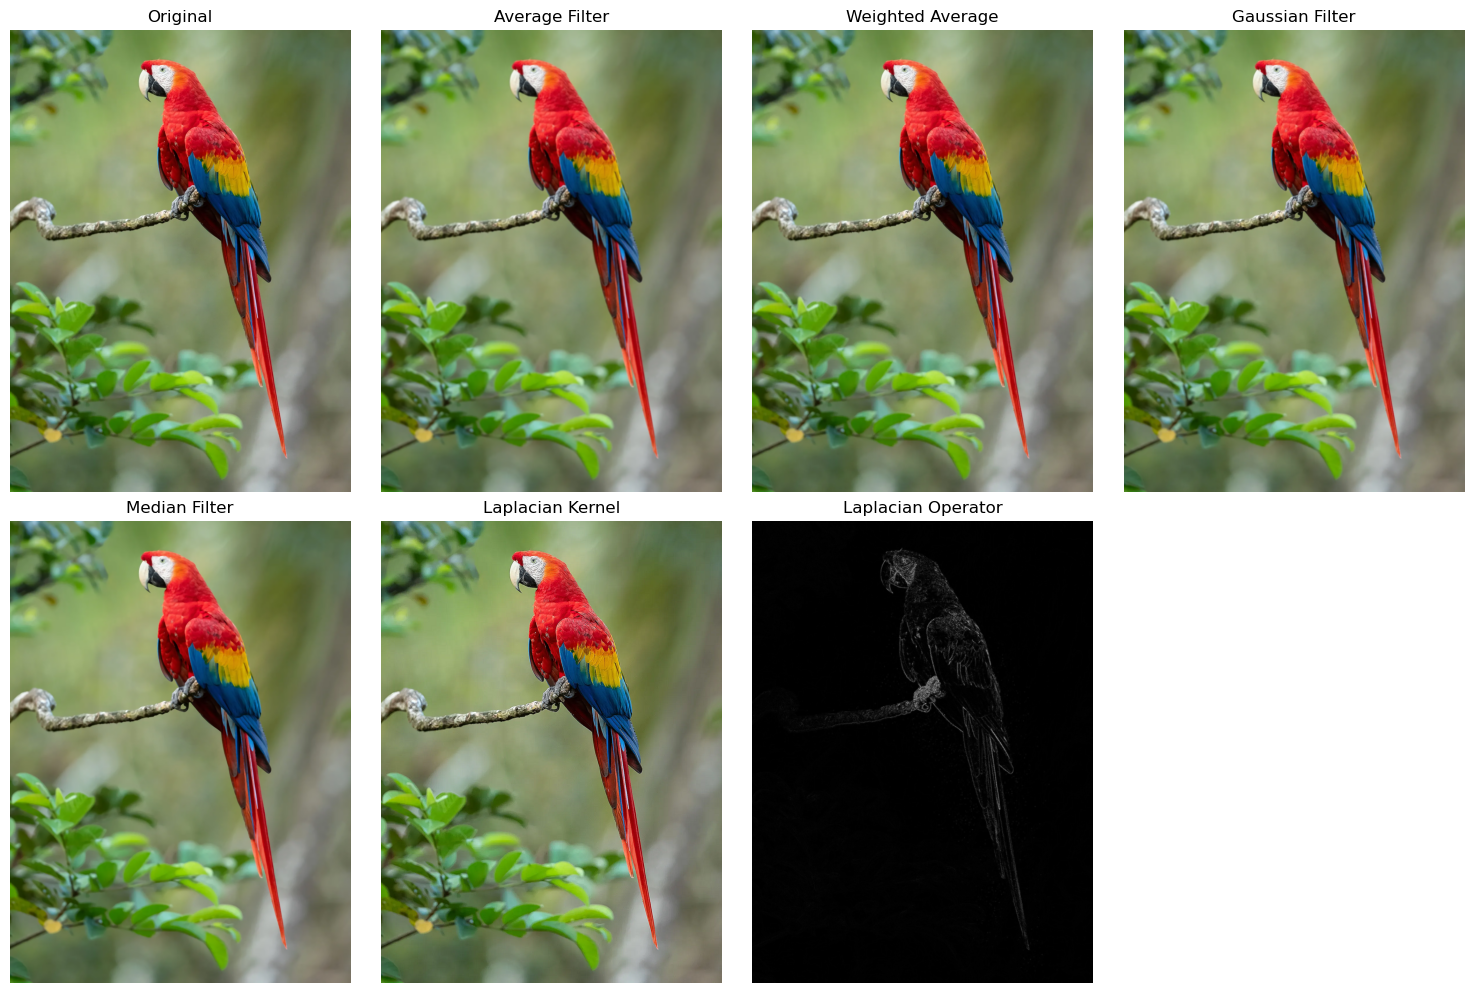

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read Image
img = cv2.imread("image.jpg")

if img is None:
    print("Image not found!")
    exit()

# Convert to RGB
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Averaging Filter
average = cv2.blur(rgb, (5,5))

# Weighted Averaging Filter
kernel = np.array([[1,2,1],
                   [2,4,2],
                   [1,2,1]], dtype=np.float32)
kernel = kernel / kernel.sum()
weighted = cv2.filter2D(rgb, -1, kernel)

# Gaussian Filter
gaussian = cv2.GaussianBlur(rgb, (5,5), 0)

# Median Filter
median = cv2.medianBlur(rgb, 5)

# Laplacian Sharpening Kernel
sharp_kernel = np.array([[0,-1,0],
                         [-1,5,-1],
                         [0,-1,0]])
lap_kernel = cv2.filter2D(rgb, -1, sharp_kernel)

# Laplacian Operator
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
lap_operator = cv2.Laplacian(gray, cv2.CV_64F)
lap_operator = np.uint8(np.absolute(lap_operator))

# Display Images
plt.figure(figsize=(15,10))

plt.subplot(2,4,1)
plt.imshow(rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(2,4,2)
plt.imshow(average)
plt.title("Average Filter")
plt.axis("off")

plt.subplot(2,4,3)
plt.imshow(weighted)
plt.title("Weighted Average")
plt.axis("off")

plt.subplot(2,4,4)
plt.imshow(gaussian)
plt.title("Gaussian Filter")
plt.axis("off")

plt.subplot(2,4,5)
plt.imshow(median)
plt.title("Median Filter")
plt.axis("off")

plt.subplot(2,4,6)
plt.imshow(lap_kernel)
plt.title("Laplacian Kernel")
plt.axis("off")

plt.subplot(2,4,7)
plt.imshow(lap_operator, cmap="gray")
plt.title("Laplacian Operator")
plt.axis("off")

plt.tight_layout()
plt.show()